# Correlação entre AGE e LIMIT_BAL — Default of Credit Card Clients (UCI)
Yeh, I. (2009). https://doi.org/10.24432/C55S3H (CC BY 4.0).

In [1]:
!pip install -q ucimlrepo scipy pandas numpy matplotlib

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from ucimlrepo import fetch_ucirepo

ds = fetch_ucirepo(id=350)
df = ds.data.features.copy()

ren = {'X1':'LIMIT_BAL','X2':'SEX','X3':'EDUCATION','X4':'MARRIAGE','X5':'AGE'}
df = df.rename(columns={k:v for k,v in ren.items() if k in df.columns})
assert {'LIMIT_BAL','AGE','SEX','EDUCATION','MARRIAGE'} <= set(df.columns), df.columns.tolist()
print(ds.metadata['name'], df.shape)
assert len(df) == 30000

Default of Credit Card Clients (30000, 23)


## Pré-processamento: ausentes, duplicadas e categorias não interpretáveis

In [3]:
print('valores ausentes:', int(df.isna().sum().sum()))
n_dup = int(df.duplicated().sum())
print(f'linhas duplicadas: {n_dup} ({n_dup/len(df):.2%} de {len(df)}) — mantidas')
print('EDUCATION fora de {1,2,3}:', int((~df.EDUCATION.isin([1,2,3])).sum()))
print('MARRIAGE fora de {1,2}:', int((~df.MARRIAGE.isin([1,2])).sum()))
print('SEX fora de {1,2}:', int((~df.SEX.isin([1,2])).sum()))

valores ausentes: 0
linhas duplicadas: 56 (0.19% de 30000) — mantidas
EDUCATION fora de {1,2,3}: 468
MARRIAGE fora de {1,2}: 377
SEX fora de {1,2}: 0


## Tabela 1 e Figura 1 — descritivas e normalidade

               media    mediana         dp   variancia_aprox    min      max  assimetria  curtose
AGE            35.49      34.00       9.22             85.01     21       79        0.73     0.04
LIMIT_BAL 167,484.32 140,000.00 129,747.66 16,834,543,504.00  10000  1000000        0.99     0.54


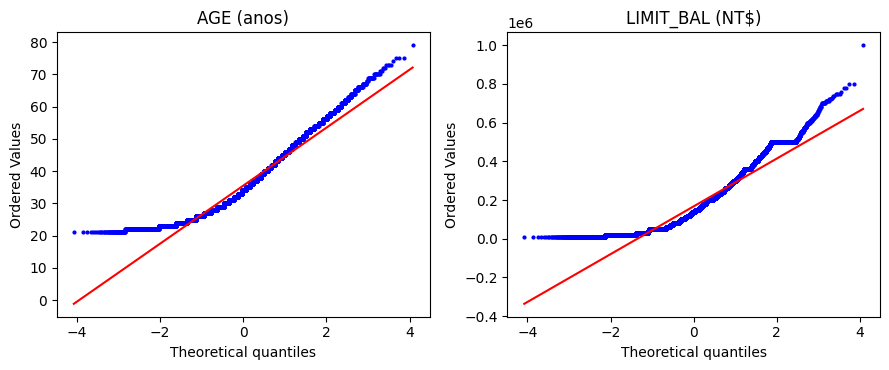

In [4]:
d = df[['AGE','LIMIT_BAL']]
dp = d.std()
dp_arr = pd.Series({'AGE': round(dp['AGE'], 2), 'LIMIT_BAL': round(dp['LIMIT_BAL'])})
t1 = pd.DataFrame({'media':d.mean(),'mediana':d.median(),'dp':dp,'variancia_aprox':dp_arr**2,
                   'min':d.min(),'max':d.max(),'assimetria':d.skew(),'curtose':d.kurt()})
print(t1.round(2).to_string(float_format=lambda x: f'{x:,.2f}'))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a, col, nome in zip(ax, ['AGE','LIMIT_BAL'], ['AGE (anos)','LIMIT_BAL (NT$)']):
    stats.probplot(df[col], dist='norm', plot=a)
    a.set_title(nome); a.get_lines()[0].set_markersize(2)
plt.tight_layout(); plt.savefig('figura1_qq.png', dpi=200); plt.show()

## Tabela 2 — coeficientes e IC 95% por bootstrap (1.000 reamostragens, semente 42)

In [5]:
def coefs(a, b):
    return (stats.spearmanr(a,b)[0], stats.pearsonr(a,b)[0],
            stats.pearsonr(a,np.log(b))[0], stats.kendalltau(a,b)[0])

def boot(a, b, fn, B=1000, seed=42):
    rng = np.random.default_rng(seed); n = len(a)
    out = []
    for _ in range(B):
        i = rng.integers(0, n, n); out.append(fn(a[i], b[i]))
    return np.array(out)

A = df['AGE'].values.astype(float); L = df['LIMIT_BAL'].values.astype(float)
names = ['Spearman','Pearson','Pearson log(LIMIT_BAL)','Kendall']
est = coefs(A, L); bs = boot(A, L, coefs)
pv = [stats.spearmanr(A,L)[1], stats.pearsonr(A,L)[1],
      stats.pearsonr(A,np.log(L))[1], stats.kendalltau(A,L)[1]]
t2 = pd.DataFrame({'coef':est,'IC95_inf':np.percentile(bs,2.5,axis=0),
                   'IC95_sup':np.percentile(bs,97.5,axis=0),'valor_p':pv}, index=names)
print(t2.assign(valor_p=t2.valor_p.map(lambda p: '< 0,001' if p < 0.001 else f'{p:.3f}')).round(4).to_string())
lo, hi = t2.loc['Spearman',['IC95_inf','IC95_sup']]
print('H1 (rho >= 0,5):', 'rejeitada' if hi < 0.5 else ('compatível com H1' if lo >= 0.5 else 'inconclusiva'))

                          coef  IC95_inf  IC95_sup  valor_p
Spearman                0.1865    0.1748    0.1976  < 0,001
Pearson                 0.1447    0.1343    0.1555  < 0,001
Pearson log(LIMIT_BAL)  0.1350    0.1234    0.1463  < 0,001
Kendall                 0.1347    0.1265    0.1427  < 0,001
H1 (rho >= 0,5): rejeitada


## Tabela 3 — dez repetições em subamostras de 50% (sementes 0 a 9)

In [6]:
rows = []
for s in range(10):
    i = np.random.default_rng(s).choice(len(df), len(df)//2, replace=False)
    sub = df.iloc[i]
    rows.append({'semente':s,'spearman':stats.spearmanr(sub.AGE,sub.LIMIT_BAL)[0],
                 'pearson':stats.pearsonr(sub.AGE,sub.LIMIT_BAL)[0]})
t3 = pd.DataFrame(rows).set_index('semente'); print(t3.round(3).to_string())
print('média:', t3.mean().round(3).to_dict()); print('desvio padrão:', t3.std().round(3).to_dict())
print('variância aproximada (dp arredondado²):', (t3.std().round(3)**2).round(6).to_dict())

         spearman  pearson
semente                   
0           0.188    0.149
1           0.194    0.151
2           0.183    0.138
3           0.196    0.156
4           0.189    0.147
5           0.185    0.143
6           0.196    0.153
7           0.184    0.140
8           0.188    0.147
9           0.177    0.138
média: {'spearman': 0.188, 'pearson': 0.146}
desvio padrão: {'spearman': 0.006, 'pearson': 0.006}
variância aproximada (dp arredondado²): {'spearman': 3.6e-05, 'pearson': 3.6e-05}


## Tabela 4 — ρ de Spearman por estrato (IC 95%, 500 reamostragens, semente 42)

In [7]:
def rho(a, b): return stats.spearmanr(a, b)[0]

def strat(col, mapping):
    r = []
    for k, lab in mapping.items():
        s = df[df[col] == k]
        b = boot(s['AGE'].values.astype(float), s['LIMIT_BAL'].values.astype(float), rho, B=500)
        r.append({'estrato':f'{col} = {lab}','n':len(s),'spearman':rho(s.AGE,s.LIMIT_BAL),
                  'IC_inf':np.percentile(b,2.5),'IC_sup':np.percentile(b,97.5)})
    return pd.DataFrame(r)


t4 = pd.concat([strat('EDUCATION',{1:'pós-graduação',2:'universidade',3:'ensino médio'}),
                strat('SEX',{1:'masculino',2:'feminino'}),
                strat('MARRIAGE',{1:'casado',2:'solteiro'})])
print(t4.round(3).to_string(index=False))

                  estrato     n  spearman  IC_inf  IC_sup
EDUCATION = pós-graduação 10585     0.380   0.364   0.397
 EDUCATION = universidade 14030     0.203   0.186   0.218
 EDUCATION = ensino médio  4917     0.042   0.015   0.075
          SEX = masculino 11888     0.197   0.177   0.215
           SEX = feminino 18112     0.193   0.179   0.207
        MARRIAGE = casado 13659     0.054   0.037   0.070
      MARRIAGE = solteiro 15964     0.297   0.282   0.313


## Tabela 5 — LIMIT_BAL por faixa etária

In [8]:
bins = [20, 29, 39, 49, 59, 100]; labs = ['21-29','30-39','40-49','50-59','60 ou mais']
df['faixa'] = pd.cut(df.AGE, bins=bins, labels=labs)
t5 = df.groupby('faixa', observed=True)['LIMIT_BAL'].agg(['count','median','mean','std'])
print(t5.round(0).astype(int).to_string())

            count  median    mean     std
faixa                                    
21-29        9618   90000  124209  105741
30-39       11238  180000  197001  131460
40-49        6464  160000  180786  136587
50-59        2341  120000  163909  141509
60 ou mais    339  160000  187847  141251


## Seção 4.4 — comparação formal entre estratos (bootstrap da diferença de ρ; 1.000 reamostragens, semente 42)

In [9]:
def diff_boot(d, col, g1, g2, B=1000, seed=42):
    rng = np.random.default_rng(seed)
    a, b = d[d[col] == g1], d[d[col] == g2]
    obs = rho(a.AGE, a.LIMIT_BAL) - rho(b.AGE, b.LIMIT_BAL)
    difs = np.empty(B)
    for i in range(B):
        ra = a.iloc[rng.integers(0, len(a), len(a))]; rb = b.iloc[rng.integers(0, len(b), len(b))]
        difs[i] = rho(ra.AGE, ra.LIMIT_BAL) - rho(rb.AGE, rb.LIMIT_BAL)
    lo, hi = np.percentile(difs, [2.5, 97.5]); return obs, lo, hi

contrastes = [('EDUCATION',1,3,'pós-graduação − ensino médio'),
              ('MARRIAGE',2,1,'solteiro − casado'),
              ('SEX',1,2,'masculino − feminino')]
for col, g1, g2, nome in contrastes:
    obs, lo, hi = diff_boot(df, col, g1, g2)
    print(f'{nome}: dif = {obs:.3f}  IC95% [{lo:.3f}; {hi:.3f}]  (IC exclui 0: {lo>0 or hi<0})')

pós-graduação − ensino médio: dif = 0.338  IC95% [0.305; 0.369]  (IC exclui 0: True)
solteiro − casado: dif = 0.242  IC95% [0.220; 0.267]  (IC exclui 0: True)
masculino − feminino: dif = 0.004  IC95% [-0.020; 0.026]  (IC exclui 0: False)


## Seção 4.5 — sensibilidade a valores discrepantes (remove LIMIT_BAL ≥ P99)

In [10]:
p99 = df.LIMIT_BAL.quantile(0.99)
trim = df[df.LIMIT_BAL < p99]
print(f'P99 = {p99:,.0f} | removidas: {len(df)-len(trim)} ({(len(df)-len(trim))/len(df):.1%}) | n = {len(trim)}')
print('spearman = %.3f | pearson = %.3f' % (rho(trim.AGE,trim.LIMIT_BAL), stats.pearsonr(trim.AGE,trim.LIMIT_BAL)[0]))

P99 = 500,000 | removidas: 928 (3.1%) | n = 29072
spearman = 0.173 | pearson = 0.125


## Figura 2 — hexbin com medianas por faixa etária

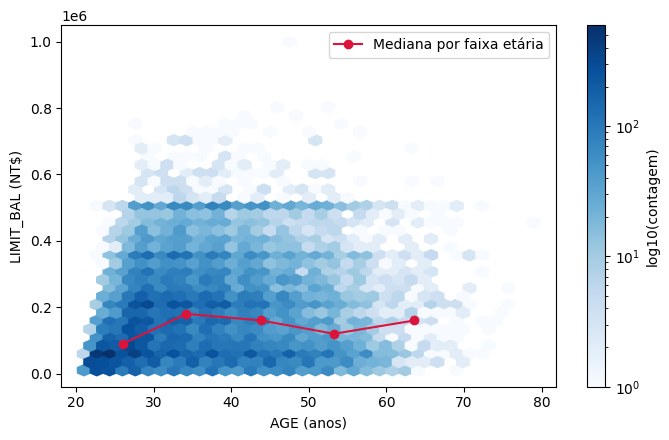

In [11]:
med = df.groupby('faixa', observed=True)['LIMIT_BAL'].median()
centros = [df.loc[df.faixa==f,'AGE'].mean() for f in med.index]
fig, a = plt.subplots(figsize=(7, 4.5))
hb = a.hexbin(df.AGE, df.LIMIT_BAL, gridsize=35, bins='log', cmap='Blues', mincnt=1)
a.plot(centros, med.values, 'o-', color='crimson', label='Mediana por faixa etária')
a.set_xlabel('AGE (anos)'); a.set_ylabel('LIMIT_BAL (NT$)')
fig.colorbar(hb, label='log10(contagem)'); a.legend()
plt.tight_layout(); plt.savefig('figura2_hexbin.png', dpi=200); plt.show()